# Intestine: tissue layers from a single ECM marker (Figure 2)

This notebook reproduces Figure 2 of the paper. It recovers the layers of the human small-intestine wall from one
extracellular-matrix (ECM) marker, collagen IV, without any cellular measurement.

- **Data:** two CODEX images of human small intestine from two donors (HuBMAP). Each has a manual annotation of
  its layers, used only for scoring.
- **Analysis:** collagen IV patches, CNN patch features, an ECM graph, then GraphMAE. These are compared with
  intensity baselines, graph controls and three other spatial methods (BANKSY, UTAG, CellCharter).
- **Run time:** about 30 minutes on one CUDA GPU. All models are trained from scratch with the paper's selected
  settings.

Requires `mantpy[patch,gnn]` 1.1.1 or newer and the packages in `intestine_requirements.txt`. Keep
`intestine_helpers.py` and `intestine_selected.json` beside this notebook.

In [ ]:
# Google Colab only: fetch this repository and install the packages. Skipped on your own computer.
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("mantpy_reproducibility"):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/moeghaf/mantpy_reproducibility"], check=True)
    os.chdir("mantpy_reproducibility/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "intestine_requirements.txt"], check=True)

In [1]:
import contextlib, inspect, io, json, time, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
from scipy import sparse
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skimage.filters import threshold_multiotsu
import torch
import mantpy as mt
from intestine_helpers import (
    load_images, pixel_annotation, PixelScorer, selected_backbone, projection_head, build_selected_graph,
    seed_everything, calculation_threads, release_cuda,
)

warnings.filterwarnings("ignore")
for name in ("pytorch_lightning", "lightning.pytorch", "lightning"):
    logging.getLogger(name).setLevel(logging.ERROR)

ALL = json.loads(Path("intestine_selected.json").read_text())
SETTINGS = ALL["images"]
TITLES = {"intestine1": "Human small intestine 1", "intestine2": "Human small intestine 2"}
LAYER_COLOURS = dict(zip(
    ["Muscularis propria", "Muscularis mucosae", "Submucosa", "Crypts", "Villus"], plt.get_cmap("tab10").colors))
MAP_SEED = {"intestine1": 4, "intestine2": 0}   # the seed drawn in the paper's Fig. 2a, b, e
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STARTED = time.perf_counter()

if "pool_size" not in inspect.signature(mt.nn.encode_patches).parameters:
    raise RuntimeError("This notebook needs Mantpy 1.1.1 or newer (the pool_size option of the patch encoder).")
if DEVICE != "cuda":
    raise RuntimeError("This notebook needs a CUDA GPU; on a CPU its model fits would take many hours.")

# Full float32 precision on the GPU, as in the paper's runs.
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

print("Mantpy", mt.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Mantpy 1.1.2.dev2+g83ae8b48f | device: NVIDIA GeForce RTX 4070 SUPER


## 1. Load both images and divide them into ECM patches

Image 1 (HuBMAP HBM926.SHNZ.594) has five annotated layers; image 2 (HBM735.PSTF.274) has four, because it
contains no muscularis propria. The annotations are used only for scoring.

`mt.pp.image_ecm_patches` clips at the 99th percentile, scales to [0, 1] and keeps the non-overlapping
32 x 32-pixel patches that contain collagen IV signal (the paper's fixed foreground thresholds). Each retained
patch becomes one ECM node.

Scores are the adjusted Rand index (ARI; 1 = perfect, 0 = chance) against the annotation, counted over the
annotated pixels inside the analysed patches.

In [2]:
loaded = load_images()
patches, scorers, windows = {}, {}, {}
for key, item in loaded.items():
    item["annotation"] = pixel_annotation(key, item, item["image"].shape)   # 0 = not annotated
    item["layers"] = [str(name) for name in item["class_names"]]
    patches[key] = mt.pp.image_ecm_patches(
        item["image"], channel_names=["ColIV"], patch_size=32, clip_percentile=99,
        pixel_thresholds=[SETTINGS[key]["pixel_threshold"]], patch_thresholds=[SETTINGS[key]["patch_threshold"]],
        feature_families=("summary",), sample_id=key, random_state=0,
    )
    scorers[key] = PixelScorer(patches[key], item["annotation"], SETTINGS[key]["k"])
    windows[key] = np.asarray(patches[key].obsm["image_patches"], dtype=np.float32)
    print(f"{TITLES[key]}: {patches[key].n_obs:,} ECM patches | " + ", ".join(item["layers"]))

scores = []   # one row per image, panel, method and seed


def record(key, panel, method, seed, labels, pixel=False):
    scores[:] = [row for row in scores                      # re-running a cell replaces its rows
                 if (row["image"], row["panel"], row["method"], row["seed"]) != (key, panel, method, seed)]
    scores.append({"image": key, "panel": panel, "method": method, "seed": seed,
                   "ARI": scorers[key].score(labels, pixel=pixel)["ARI"]})
    return scores[-1]["ARI"]

Human small intestine 1: 13,376 ECM patches | Muscularis propria, Muscularis mucosae, Submucosa, Crypts, Villus


Human small intestine 2: 9,449 ECM patches | Villus, Crypts, Muscularis mucosae, Submucosa


## 2. The three fitting steps

- **CNN patch features** (`mt.nn.PatchEncoder` / `mt.nn.encode_patches`): a small convolutional network learns a
  96-number description of each patch without labels (contrastive learning).
- **ECM graph** (`mt.gr.build_patch_graph`, through the companion helper, which also makes the shuffled-edge and
  no-edge controls): each patch is joined to its nearest patches, and each edge carries its length and orientation.
- **GraphMAE** (`mt.nn.encode_graphmae`): a graph masked autoencoder hides half of the node features and learns to
  reconstruct them from neighbouring patches, so each embedding describes a patch in its tissue context.

In [3]:
def train_cnn(key, seed, architecture, drawn_twice):
    """CNN patch features. `drawn_twice` selects the starting-weight draw used by the paper's run."""
    if not drawn_twice:
        data = patches[key].copy()
        mt.nn.encode_patches(
            data, latent_dim=96, conv_blocks=architecture["blocks"], conv_width=architecture["width"],
            pool_size=int(architecture["readout"][-1]), max_epochs=200, accelerator=DEVICE, random_state=seed,
            enable_progress_bar=False, enable_model_summary=False,
        )
        return np.asarray(data.obsm["X_cnn"], dtype=np.float32)
    seed_everything(seed, threads=2)
    encoder = mt.nn.PatchEncoder(
        latent_dim=96, temperature=0.2, augment="default",
        backbone=selected_backbone, backbone_kwargs=dict(in_channels=1, architecture=architecture, latent_dim=96),
        projection=projection_head, projection_kwargs=dict(latent_dim=96, projection_dim=64),
    ).fit(windows[key], max_epochs=200, batch_size=1024, lr=1e-3, weight_decay=1e-5, random_state=seed,
          accelerator=DEVICE, num_workers=0, drop_last=None, exhaust_sampler=True, deterministic="warn",
          enable_progress_bar=False, enable_model_summary=False)
    raw = encoder.transform(windows[key], batch_size=4096, standardize=False).astype(np.float32)
    return StandardScaler().fit_transform(raw).astype(np.float32)


def train_graphmae(key, seed, features, control=None):
    """GraphMAE embeddings on the selected ECM graph (or a control graph) of one image."""
    selected = SETTINGS[key]["joint"]
    seed_everything(seed, threads=2)
    data = patches[key].copy()
    del data.obsm["image_patches"]
    data.obsm["X_cnn"] = features
    build_selected_graph(data, selected["neighbours"], selected["continuity_thresh"], control=control, seed=seed)
    mt.nn.encode_graphmae(
        data, graph_key="patch", node_feature_key="X_cnn", key_added="X_graphmae",
        encoder="gine", hidden_dim=128, n_layers=4, mask_ratio=0.5,
        decoder="graphmae_remask", norm="layernorm", mitigation="jk", recon_loss="scaled_cosine",
        max_epochs=200, lr=1e-3, weight_decay=1e-4, standardize=False,
        random_state=seed, accelerator=DEVICE, enable_progress_bar=False,
    )
    release_cuda()
    return np.asarray(data.obsm["X_graphmae"], dtype=np.float32)


def cluster(key, matrix):
    with calculation_threads(2):
        return KMeans(n_clusters=SETTINGS[key]["k"], **ALL["kmeans"]["joint"]).fit_predict(matrix)


JOINT_CNN = {key: {name: SETTINGS[key]["joint"]["cnn_" + name] for name in ("blocks", "width", "readout", "activation")}
             for key in SETTINGS}

## 3. Three levels of spatial context (Figure 2a, b)

1. **Pixel K-means**: intensity only (scikit-learn, fitted on two million sampled pixels).
2. **CNN K-means**: each patch on its own.
3. **GraphMAE**: each patch with its neighbours on the ECM graph (120 neighbours in image 1, 160 in image 2).

The CNN and GraphMAE are fitted here for the seed shown in the paper's maps (seed 4 in image 1, seed 0 in
image 2); the other seeds follow in section 4. Patch-mean K-means and Multi-Otsu, two further intensity baselines
used in Fig. 2c, are fitted here too.

In [4]:
shown, joint_features = {key: {} for key in loaded}, {}
for key, item in loaded.items():
    t = time.perf_counter()
    k, clip, raw = SETTINGS[key]["k"], SETTINGS[key]["clip"], item["image"]

    # intensity baselines (single runs)
    chosen = np.sort(np.random.default_rng(0).choice(raw.size, 2_000_000, replace=False))
    sample = (np.minimum(raw.ravel()[chosen].astype(np.float32), clip) / clip)[:, None]
    with calculation_threads(8):
        centres = KMeans(n_clusters=k, random_state=0).fit(sample).cluster_centers_.ravel()
    pixel_labels = np.empty(raw.shape, dtype=np.uint8)
    for row in range(0, raw.shape[0], 512):
        scaled = np.minimum(raw[row:row + 512].astype(np.float32), clip) / clip
        pixel_labels[row:row + 512] = np.argmin(np.abs(scaled[..., None] - centres[None, None, :]), axis=-1)
    means = windows[key].reshape(len(windows[key]), -1).mean(1)
    with calculation_threads(8):
        patch_labels = KMeans(n_clusters=k, random_state=0).fit_predict(means[:, None])
    pixel_ari = record(key, "c, baseline", "Pixel K-means", 0, pixel_labels, pixel=True)
    record(key, "c, baseline", "Patch-mean K-means", 0, patch_labels)
    record(key, "c, baseline", "Multi-Otsu", 0, np.digitize(means, threshold_multiotsu(means, classes=k)))
    shown[key]["Pixel K-means"] = np.array([     # most frequent pixel cluster in each patch, for the maps
        np.bincount(pixel_labels[y * 32:(y + 1) * 32, x * 32:(x + 1) * 32].ravel(), minlength=k).argmax()
        for y, x in patches[key].obs[["grid_y", "grid_x"]].to_numpy(int)])
    item["display"] = np.minimum(raw[::8, ::8].astype(np.float32), clip) / clip

    # CNN and GraphMAE for the seed shown in the paper (starting weights: seeds 0-3 drawn once, seed 4 drawn twice)
    seed = MAP_SEED[key]
    joint_features[key, seed] = train_cnn(key, seed, JOINT_CNN[key], drawn_twice=seed == 4)
    shown[key]["CNN K-means"] = cluster(key, joint_features[key, seed])
    shown[key]["GraphMAE"] = cluster(key, train_graphmae(key, seed, joint_features[key, seed]))
    item["shown_ari"] = {
        "Pixel K-means": pixel_ari,
        "CNN K-means": record(key, "d", "CNN K-means", seed, shown[key]["CNN K-means"]),
        "GraphMAE": record(key, "d", "GraphMAE, full graph", seed, shown[key]["GraphMAE"]),
    }
    print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)

paper_shown = {"intestine1": [0.2029, 0.4471, 0.9023], "intestine2": [0.0098, 0.0289, 0.4232]}   # fig2.xlsx: a_seeds, b_seeds
pd.concat({
    f"{TITLES[key]} (seed {MAP_SEED[key]})": pd.DataFrame({
        "spatial context": ["none", "patch", "patch + neighbours"],
        "ARI, this run": list(item["shown_ari"].values()),
        "ARI, paper (same seed)": paper_shown[key],
    }, index=list(item["shown_ari"]))
    for key, item in loaded.items()
}).round(3)

Human small intestine 1, seed 4: 71 s


Human small intestine 2, seed 0: 58 s


spatial context  \
Human small intestine 1 (seed 4) Pixel K-means                none   
                                 CNN K-means                 patch   
                                 GraphMAE       patch + neighbours   
Human small intestine 2 (seed 0) Pixel K-means                none   
                                 CNN K-means                 patch   
                                 GraphMAE       patch + neighbours   

                                                ARI, this run  \
Human small intestine 1 (seed 4) Pixel K-means          0.196   
                                 CNN K-means            0.447   
                                 GraphMAE               0.903   
Human small intestine 2 (seed 0) Pixel K-means          0.010   
                                 CNN K-means            0.029   
                                 GraphMAE               0.422   

                                                ARI, paper (same seed)  
Human small intestine 1 (seed 4) Pixel K-means                   0.203  
                                 CNN K-means                     0.447  
                                 GraphMAE                        0.902  
Human small intestine 2 (seed 0) Pixel K-means                   0.010  
                                 CNN K-means                     0.029  
                                 GraphMAE                        0.423

### Maps (Figure 2a, b) and recovery of each layer

`mt.pl.patch_map` draws per-patch labels on the patch grid. Clusters are matched one-to-one to the annotated
layers and coloured by their matched layer, with the same colours in both images. The table gives the
percentage of each annotated layer's pixels that fall in its matched GraphMAE domain.

,Human small intestine 1,Human small intestine 2
Muscularis propria,100.0,NaN
Muscularis mucosae,80.0,67.0
Submucosa,88.0,88.0
Crypts,80.0,68.0
Villus,96.0,49.0


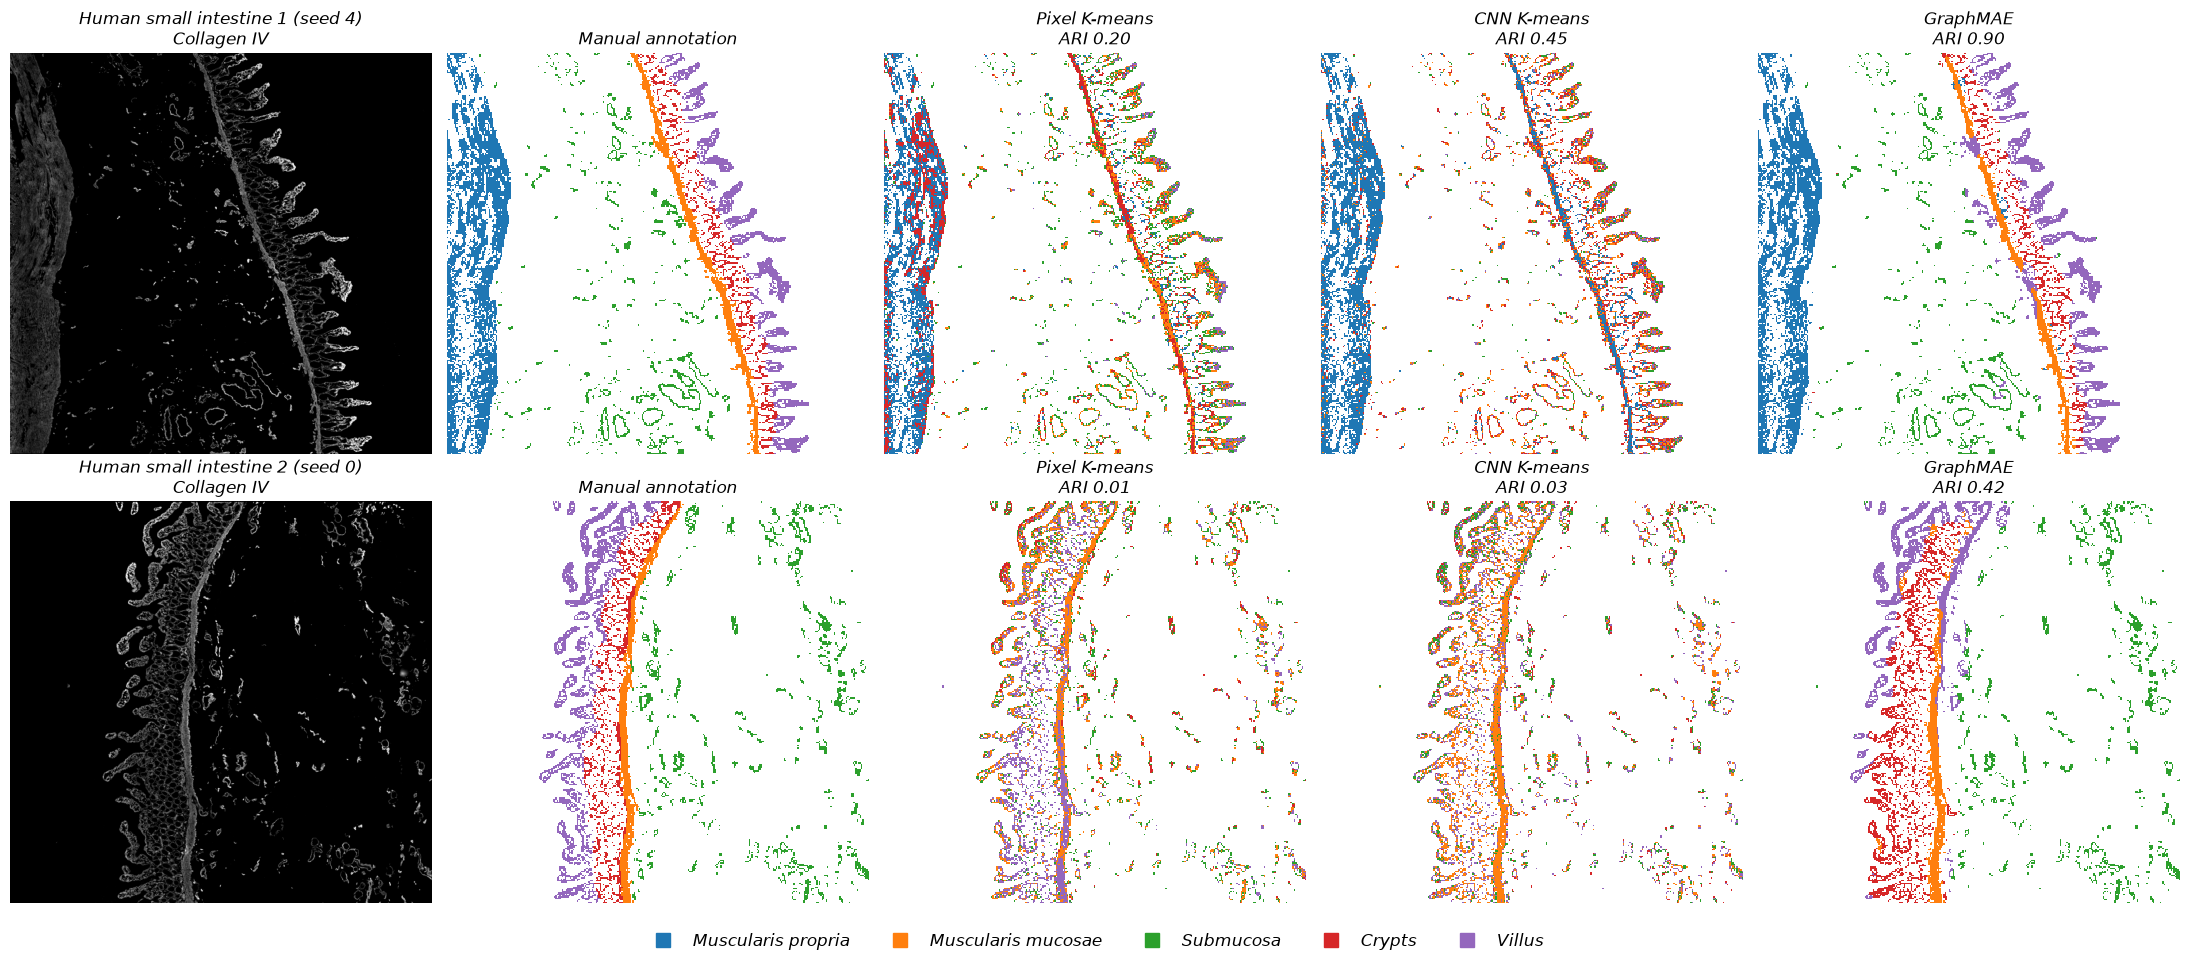

In [5]:
matched, recovery = {}, {}
for key, item in loaded.items():
    k, counts = SETTINGS[key]["k"], scorers[key].counts
    matched[key] = {"Manual annotation": np.where(counts.sum(1) > 0, counts.argmax(1), -1)}   # -1 = not annotated
    for method, partition in shown[key].items():
        overlap = scorers[key].contingency(partition)[:, :k]     # annotated pixels: layer x cluster
        layer, cluster_id = linear_sum_assignment(-overlap)
        matched[key][method] = layer[np.argsort(cluster_id)][partition]
        if method == "GraphMAE":
            overlap = overlap[:, cluster_id[np.argsort(layer)]]
            recovery[TITLES[key]] = pd.Series(np.diag(overlap) / overlap.sum(1) * 100, index=item["layers"])
display(pd.DataFrame(recovery).reindex(list(LAYER_COLOURS)).round(0))

figure, axes = plt.subplots(2, 5, figsize=(22, 9.5))
for row, (key, item) in enumerate(loaded.items()):
    palette = {i: LAYER_COLOURS[name] for i, name in enumerate(item["layers"])}
    axes[row, 0].imshow(item["display"], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"{TITLES[key]} (seed {MAP_SEED[key]})\nCollagen IV", fontsize=12)
    for axis, (method, values) in zip(axes[row, 1:], matched[key].items()):
        mt.pl.patch_map(patches[key], values, ax=axis, categorical=True, palette=palette, crop=False, background="white")
        axis.set_title(method if method not in item["shown_ari"] else f"{method}\nARI {item['shown_ari'][method]:.2f}", fontsize=12)
for axis in axes.ravel():
    axis.set_axis_off()
handles = [plt.Line2D([], [], marker="s", linestyle="", markersize=10, color=colour, label=name)
           for name, colour in LAYER_COLOURS.items()]
figure.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=12)
figure.tight_layout(rect=(0, 0.04, 1, 1), h_pad=3)
plt.show()

### GraphMAE domains (Figure 2e)

Each GraphMAE domain is shown against the other analysed patches (grey), named by its matched layer.

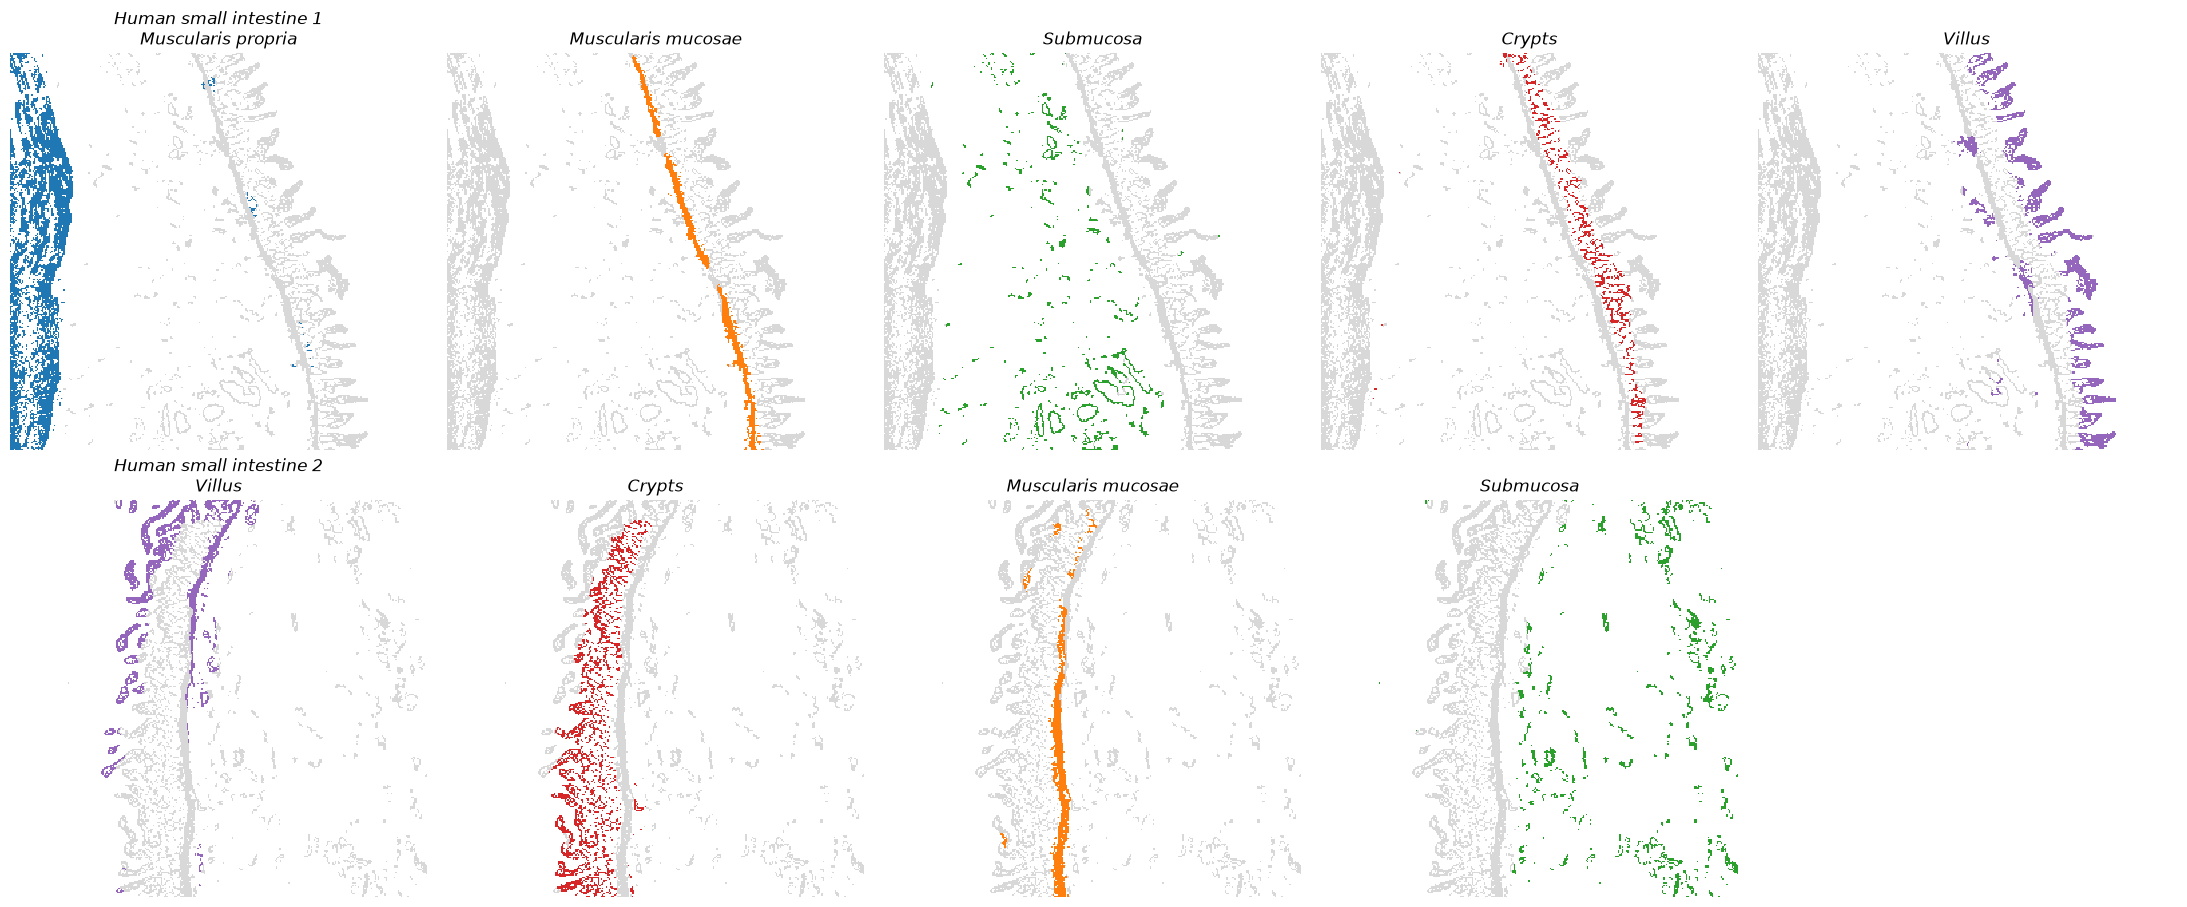

In [6]:
figure, axes = plt.subplots(2, 5, figsize=(22, 9))
for row, (key, item) in enumerate(loaded.items()):
    for column, axis in enumerate(axes[row]):
        axis.set_axis_off()
        if column >= SETTINGS[key]["k"]:
            continue
        name = item["layers"][column]
        mt.pl.patch_map(
            patches[key], np.where(matched[key]["GraphMAE"] == column, 0, 1), ax=axis, categorical=True,
            palette={0: LAYER_COLOURS[name], 1: (0.85, 0.85, 0.85)}, crop=False, background="white",
        )
        axis.set_title(f"{TITLES[key]}\n{name}" if column == 0 else name, fontsize=12)
        axis.set_axis_off()
figure.tight_layout(h_pad=3)
plt.show()

## 4. Graph controls and five training seeds (Figure 2d)

For each image and each of five training seeds, the same GraphMAE is refitted on the same CNN features with
every edge's destination shuffled, and with all edges removed. The CNN and full-graph fits of the remaining seeds
are added here, giving the five-seed means quoted for Fig. 2a, b. K-means uses the same initialisation seed for
every training seed in these panels, as in the paper's runs.

Human small intestine 1, seed 0: 106 s


Human small intestine 1, seed 1: 105 s


Human small intestine 1, seed 2: 106 s


Human small intestine 1, seed 3: 105 s


Human small intestine 1, seed 4: 42 s


Human small intestine 2, seed 0: 39 s


... (2 outputs left out)

Human small intestine 2, seed 3: 93 s


Human small intestine 2, seed 4: 93 s


this run          paper
image                   method                                                
Human small intestine 1 CNN K-means               0.451 ± 0.006  0.451 ± 0.006
                        GraphMAE, shuffled edges  0.001 ± 0.001  0.001 ± 0.001
                        GraphMAE, no edges        0.243 ± 0.035  0.243 ± 0.035
                        GraphMAE, full graph      0.897 ± 0.017  0.897 ± 0.017
Human small intestine 2 CNN K-means               0.024 ± 0.004  0.024 ± 0.004
                        GraphMAE, shuffled edges  0.000 ± 0.000  0.000 ± 0.000
                        GraphMAE, no edges        0.039 ± 0.012  0.039 ± 0.012
                        GraphMAE, full graph      0.420 ± 0.027  0.418 ± 0.030

seed                                                  0      1      2      3  \
image                   method                                                 
Human small intestine 1 CNN K-means               0.461  0.445  0.450  0.453   
                        GraphMAE, shuffled edges  0.001  0.003  0.000  0.001   
                        GraphMAE, no edges        0.289  0.244  0.195  0.257   
                        GraphMAE, full graph      0.870  0.903  0.915  0.893   
Human small intestine 2 CNN K-means               0.029  0.022  0.024  0.026   
                        GraphMAE, shuffled edges  0.000  0.000  0.000  0.000   
                        GraphMAE, no edges        0.058  0.027  0.035  0.040   
                        GraphMAE, full graph      0.422  0.431  0.415  0.452   

seed                                                  4  
image                   method                           
Human small intestine 1 CNN K-means               0.447  
                        GraphMAE, shuffled edges  0.001  
                        GraphMAE, no edges        0.231  
                        GraphMAE, full graph      0.903  
Human small intestine 2 CNN K-means               0.019  
                        GraphMAE, shuffled edges  0.001  
                        GraphMAE, no edges        0.034  
                        GraphMAE, full graph      0.379

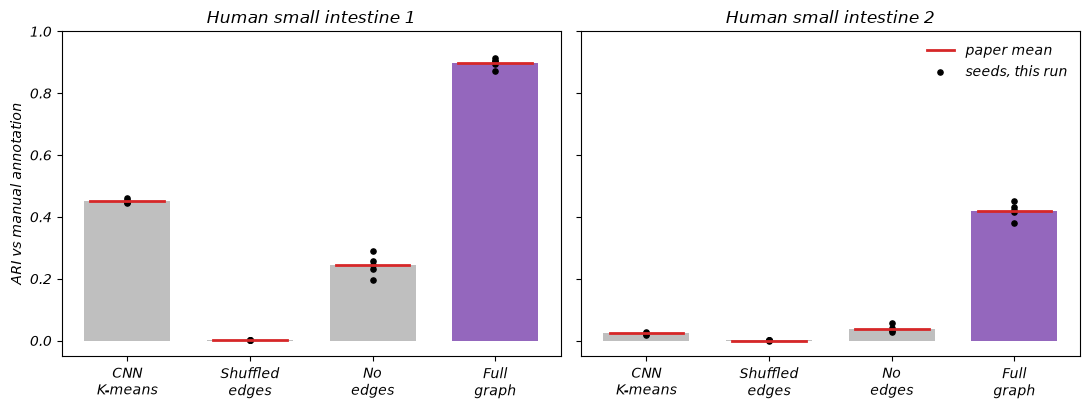

In [7]:
for key in loaded:
    for seed in ALL["seeds"]["joint"]:
        t = time.perf_counter()
        if (key, seed) not in joint_features:     # the seed shown in the maps was fitted in section 3
            # paper seeds 0-3: starting weights drawn once; seed 4: drawn twice
            joint_features[key, seed] = train_cnn(key, seed, JOINT_CNN[key], drawn_twice=seed == 4)
            record(key, "d", "CNN K-means", seed, cluster(key, joint_features[key, seed]))
            record(key, "d", "GraphMAE, full graph", seed, cluster(key, train_graphmae(key, seed, joint_features[key, seed])))
        for method, control in (("GraphMAE, shuffled edges", "shuffled_edges"), ("GraphMAE, no edges", "no_edges")):
            record(key, "d", method, seed, cluster(key, train_graphmae(key, seed, joint_features[key, seed], control)))
        print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)

PAPER_D = {   # mean, s.d. over five seeds (source data fig2.xlsx, sheet d_means)
    ("intestine1", "CNN K-means"): (0.451, 0.006), ("intestine1", "GraphMAE, shuffled edges"): (0.001, 0.001),
    ("intestine1", "GraphMAE, no edges"): (0.243, 0.035), ("intestine1", "GraphMAE, full graph"): (0.897, 0.017),
    ("intestine2", "CNN K-means"): (0.024, 0.004), ("intestine2", "GraphMAE, shuffled edges"): (0.000, 0.000),
    ("intestine2", "GraphMAE, no edges"): (0.039, 0.012), ("intestine2", "GraphMAE, full graph"): (0.418, 0.030),
}
table = pd.DataFrame(scores)
d = table[table.panel == "d"]
summary_d = d.groupby(["image", "method"])["ARI"].agg(["mean", "std"]).reindex(list(PAPER_D))
summary_d["this run"] = summary_d["mean"].map("{:.3f}".format) + " ± " + summary_d["std"].map("{:.3f}".format)
summary_d["paper"] = [f"{m:.3f} ± {s:.3f}" for m, s in PAPER_D.values()]
display(summary_d[["this run", "paper"]].rename(index=TITLES, level=0))
display(d.pivot(index=["image", "method"], columns="seed", values="ARI").reindex(list(PAPER_D)).round(3)
        .rename(index=TITLES, level=0))

order = ["CNN K-means", "GraphMAE, shuffled edges", "GraphMAE, no edges", "GraphMAE, full graph"]
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for axis, key in zip(axes, loaded):
    for i, method in enumerate(order):
        values = d[(d.image == key) & (d.method == method)]["ARI"].to_numpy()
        axis.bar(i, values.mean(), color="tab:purple" if "full" in method else "0.75", width=0.7)
        axis.scatter(np.full(len(values), i), values, color="black", s=14, zorder=3)
        axis.plot([i - 0.3, i + 0.3], [PAPER_D[key, method][0]] * 2, color="tab:red", linewidth=2, zorder=4)
    axis.set_xticks(range(4), ["CNN\nK-means", "Shuffled\nedges", "No\nedges", "Full\ngraph"])
    axis.set_title(TITLES[key])
    axis.set_ylim(-0.05, 1)
axes[0].set_ylabel("ARI vs manual annotation")
axes[1].plot([], [], color="tab:red", linewidth=2, label="paper mean")
axes[1].scatter([], [], color="black", s=14, label="seeds, this run")
axes[1].legend(frameon=False)
figure.tight_layout()
plt.show()

## 5. Method comparison (Figure 2c)

The same patches and CNN features are analysed by GraphMAE (through PyTorch Geometric) and by BANKSY, UTAG and
CellCharter (external packages, through AnnData). Each external method receives the patch `AnnData` holding the
CNN features and coordinates in micrometres, applies its own neighbourhood transformation, and is clustered at
the number of annotated layers.

For this comparison the paper chose a CNN independently of GraphMAE (32 channels wide), and all its starting
weights were drawn twice. The GraphMAE in this panel uses a GIN encoder without edge features, two layers and 75%
masking, on 240 (image 1) or 80 (image 2) neighbours, as selected in the paper. K-means is re-seeded with each
training seed.

In [8]:
from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix
from utag import utag
import cellcharter as cc
import squidpy as sq


def patch_anndata(key, features):
    data = ad.AnnData(X=features.copy(), obs=pd.DataFrame(
        {"sample_id": pd.Categorical([key] * len(features))}, index=patches[key].obs_names.copy()))
    data.obsm["spatial"] = np.asarray(patches[key].obsm["spatial"]) * ALL["pixel_size_um"]
    return data


def run_banksy(key, features, config, seed, n_init):
    data = patch_anndata(key, features)
    data.obs["x"], data.obs["y"] = data.obsm["spatial"][:, 0], data.obsm["spatial"][:, 1]
    banksy = initialize_banksy(
        data, coord_keys=("x", "y", "spatial"), num_neighbours=config["k"], nbr_weight_decay="scaled_gaussian",
        max_m=config["max_m"], plt_edge_hist=False, plt_nbr_weights=False, plt_agf_angles=False, plt_theta=False)
    banksy, _ = generate_banksy_matrix(data, banksy, lambda_list=[config["lambda"]], max_m=config["max_m"], verbose=False)
    matrix = banksy["scaled_gaussian"][config["lambda"]]["adata"].X
    matrix = matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)
    embedding = PCA(n_components=config["pca"], random_state=seed).fit_transform(matrix.astype(np.float32))
    return KMeans(n_clusters=SETTINGS[key]["k"], n_init=n_init, random_state=seed).fit_predict(embedding)


def run_utag(key, features, config, seed, n_init):
    matrix = utag(patch_anndata(key, features), slide_key=None, max_dist=config["radius_um"],
                  normalization_mode=config["normalization"], apply_clustering=False, parallel=False).X
    matrix = matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)
    embedding = PCA(n_components=config["pca"], random_state=seed).fit_transform(matrix.astype(np.float32))
    return KMeans(n_clusters=SETTINGS[key]["k"], n_init=n_init, random_state=seed).fit_predict(embedding)


def run_cellcharter(key, features, config, seed, n_init=None):
    data = patch_anndata(key, features)
    if config["graph"] == "native_knn6":
        sq.gr.spatial_neighbors(data, coord_type="generic", n_neighs=6, library_key="sample_id")
        connectivity = "spatial_connectivities"
    else:   # the Mantpy patch graph with the stated number of neighbours
        geometry = patches[key].copy()
        del geometry.obsm["image_patches"]
        mt.gr.build_patch_graph(geometry, k=int(config["graph"].split("_k")[1]), continuity_thresh=0.25,
                                continuity_samples=6, key_added="patch")
        edges = np.asarray(geometry.uns["patch"]["edge_index"])
        connectivity = "mantpy_connectivities"
        data.obsp[connectivity] = sparse.csr_matrix((np.ones(edges.shape[1]), (edges[0], edges[1])),
                                                    shape=(len(features), len(features)))
    cc.gr.aggregate_neighbors(data, n_layers=config["hops"], aggregations="mean",
                              connectivity_key=connectivity, sample_key="sample_id")
    estimator = cc.tl.Cluster(n_clusters=SETTINGS[key]["k"], covariance_type="full", random_state=seed,
                              trainer_params={"accelerator": "cpu", "enable_progress_bar": False})
    estimator.fit(data)
    return np.asarray(estimator.predict(data), dtype=np.int64)


COMPARATORS = {"BANKSY": ("banksy", run_banksy), "UTAG": ("utag", run_utag), "CellCharter": ("cellcharter", run_cellcharter)}


def run_quietly(run, *arguments):
    """Run an external method with its progress messages hidden."""
    with contextlib.redirect_stdout(io.StringIO()), calculation_threads(4):
        return run(*arguments)


def show_maps(key, partitions, heading, ari=None):
    """One row of maps: the manual annotation, then each partition coloured by its matched layer."""
    item, k = loaded[key], SETTINGS[key]["k"]
    palette = {i: LAYER_COLOURS[name] for i, name in enumerate(item["layers"])}
    figure, axes = plt.subplots(1, len(partitions) + 1, figsize=(4.2 * (len(partitions) + 1), 4.6))
    mt.pl.patch_map(patches[key], matched[key]["Manual annotation"], ax=axes[0], categorical=True,
                    palette=palette, crop=False, background="white")
    axes[0].set_title(f"{heading}\nManual annotation", fontsize=12)
    for axis, (method, partition) in zip(axes[1:], partitions.items()):
        partition = np.searchsorted(np.unique(partition), partition)
        overlap = scorers[key].contingency(partition)[:, :k]
        layer, cluster_id = linear_sum_assignment(-overlap)
        mt.pl.patch_map(patches[key], layer[np.argsort(cluster_id)][partition], ax=axis, categorical=True,
                        palette=palette, crop=False, background="white")
        score = (ari or {}).get(method, scorers[key].score(partition)["ARI"])
        axis.set_title(f"{method}\nARI {score:.2f}", fontsize=12)
    for axis in axes:
        axis.set_axis_off()
    handles = [plt.Line2D([], [], marker="s", linestyle="", markersize=9, color=LAYER_COLOURS[name], label=name)
               for name in item["layers"]]
    figure.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=11)
    figure.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

### Selected settings, three seeds

The CNN and each method's neighbourhood setting were chosen in the paper without the annotation, by seed
stability. Only the selected settings are refitted here. The maps of every method are drawn as each seed
finishes.

Human small intestine 1, seed 0: 81 s


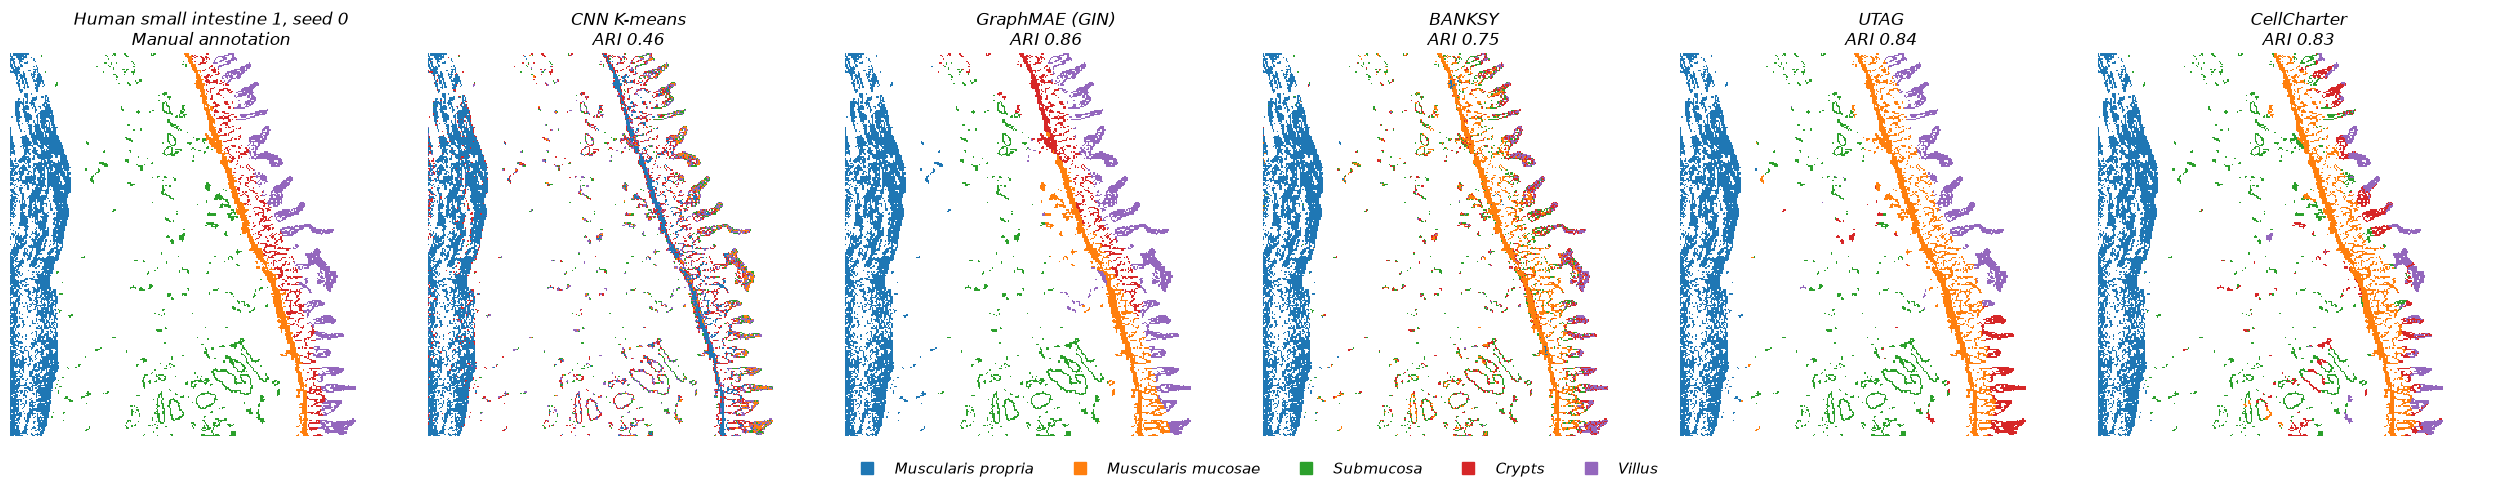

Human small intestine 1, seed 1: 92 s


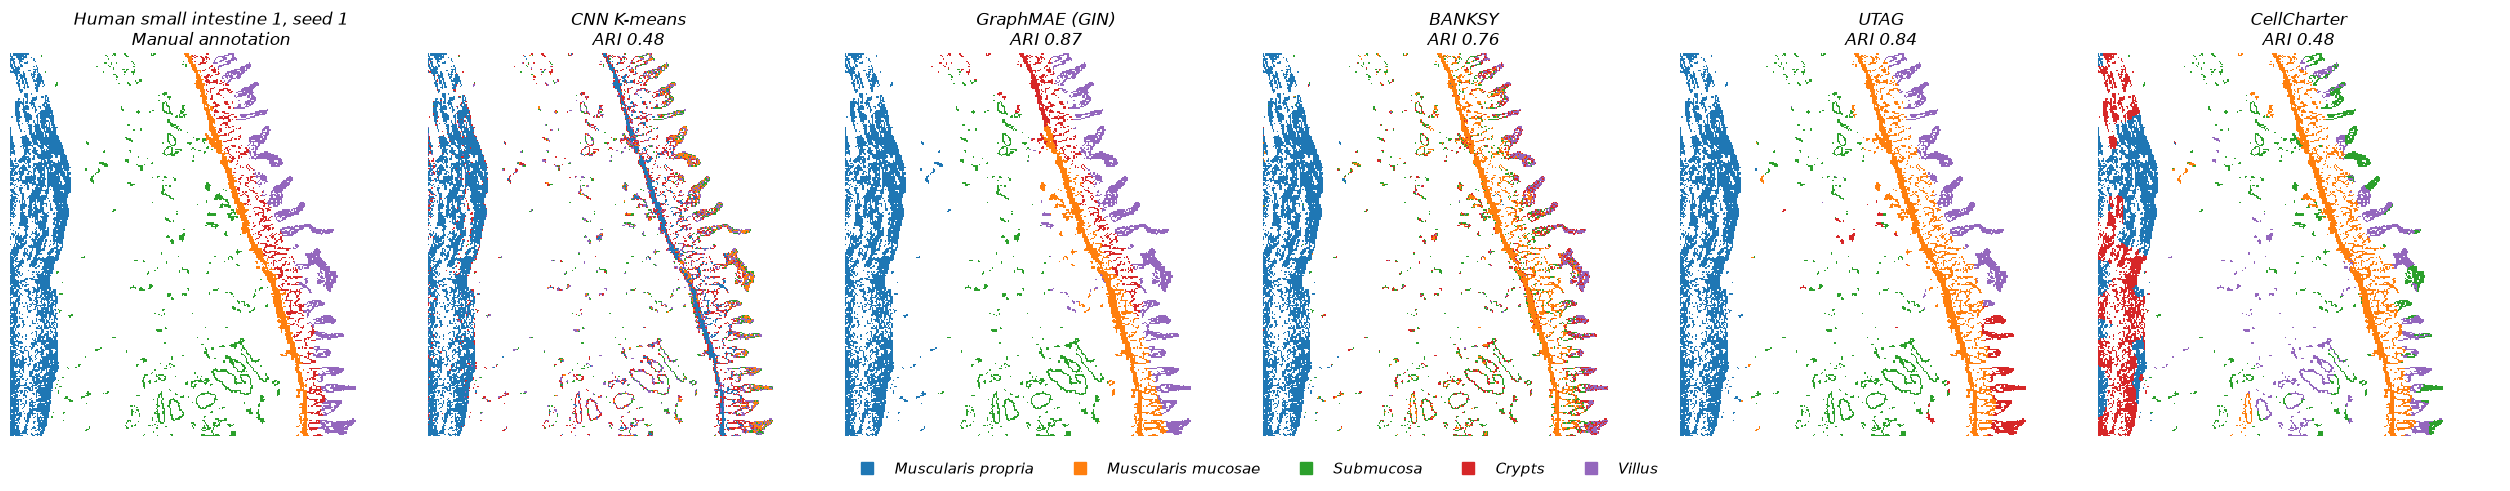

Human small intestine 1, seed 2: 85 s


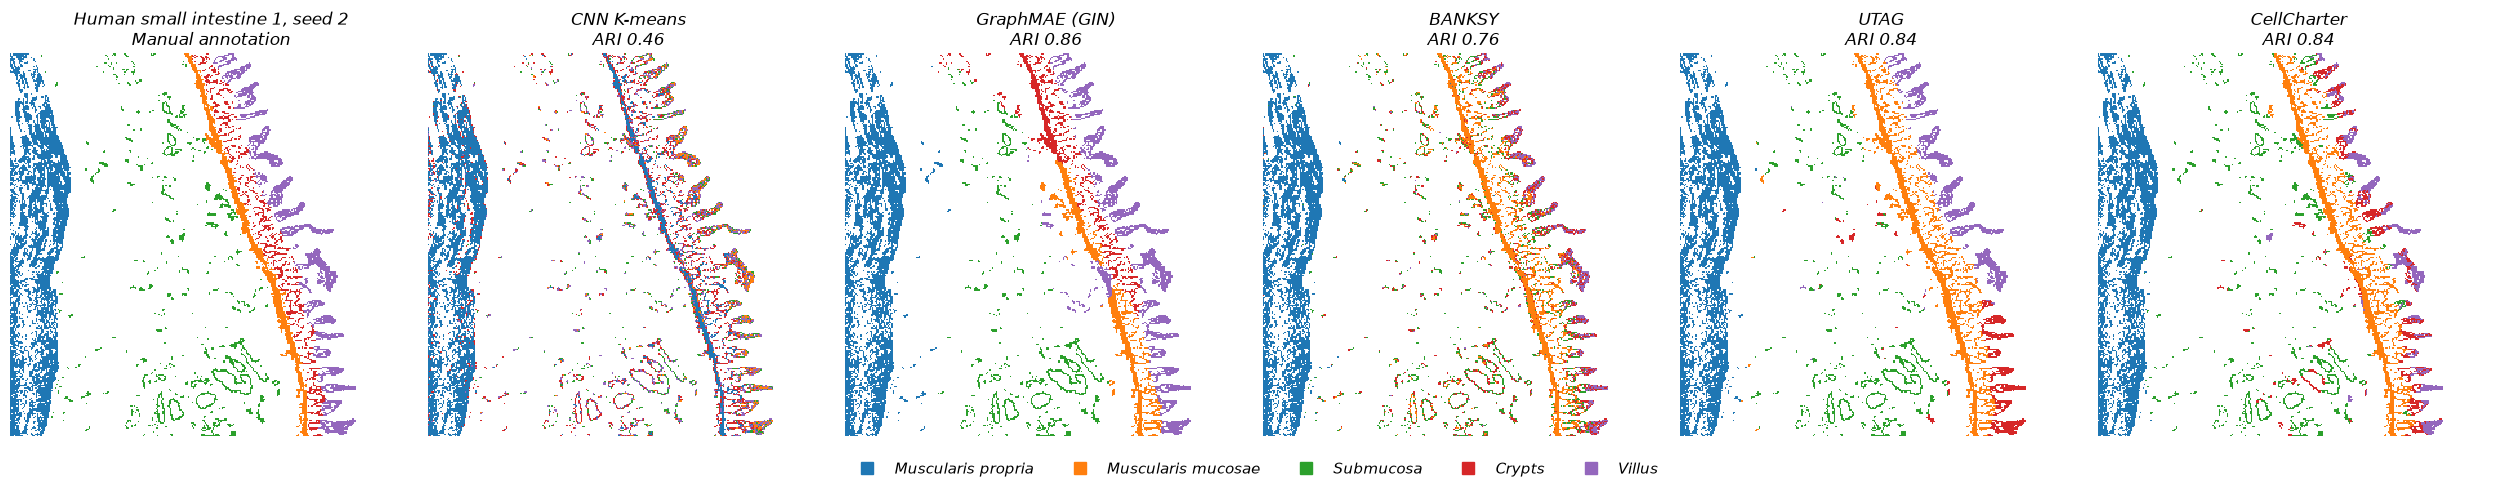

Human small intestine 2, seed 0: 63 s


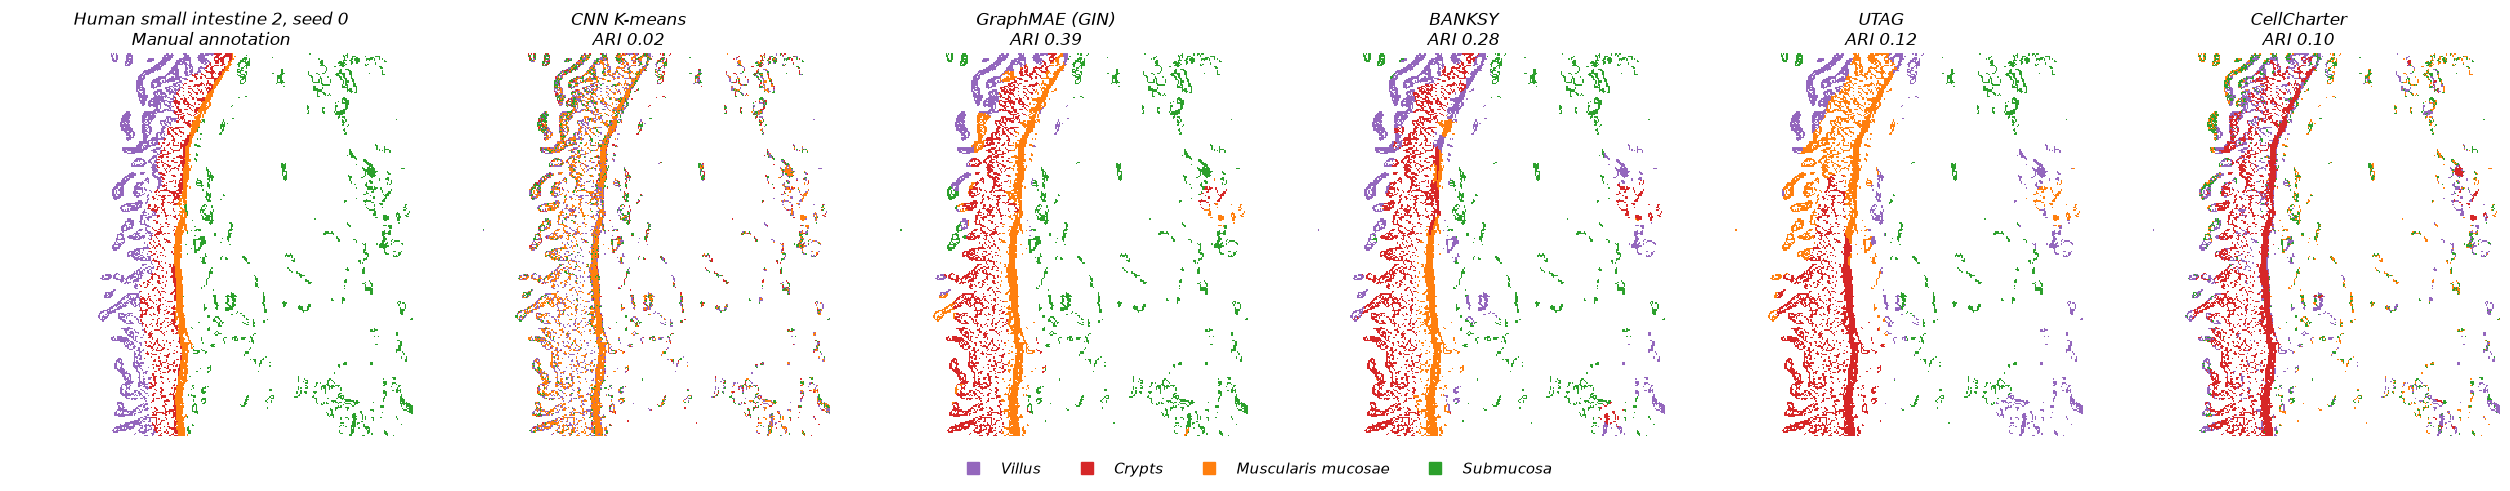

Human small intestine 2, seed 1: 60 s


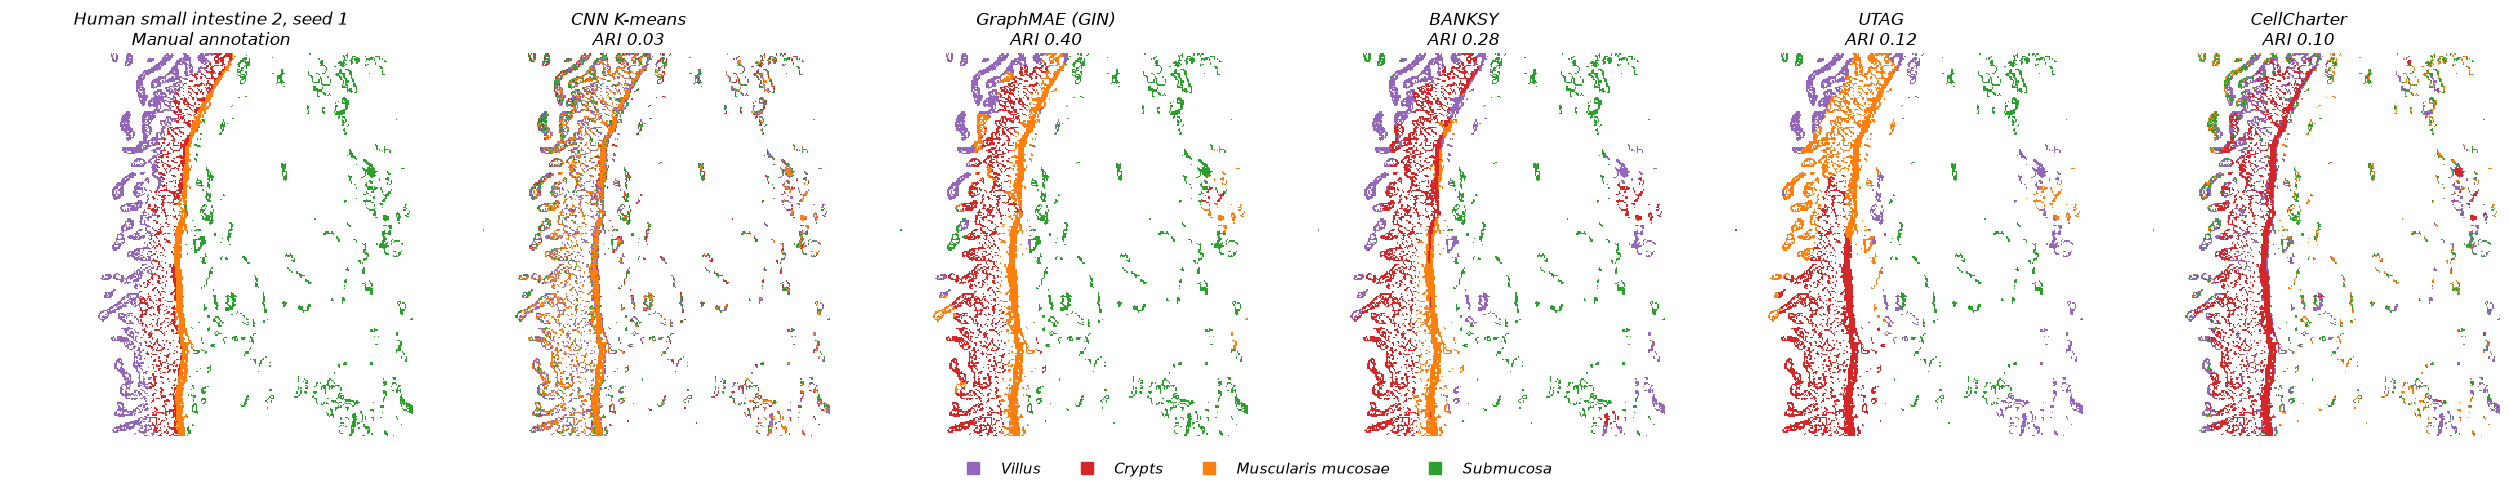

Human small intestine 2, seed 2: 65 s


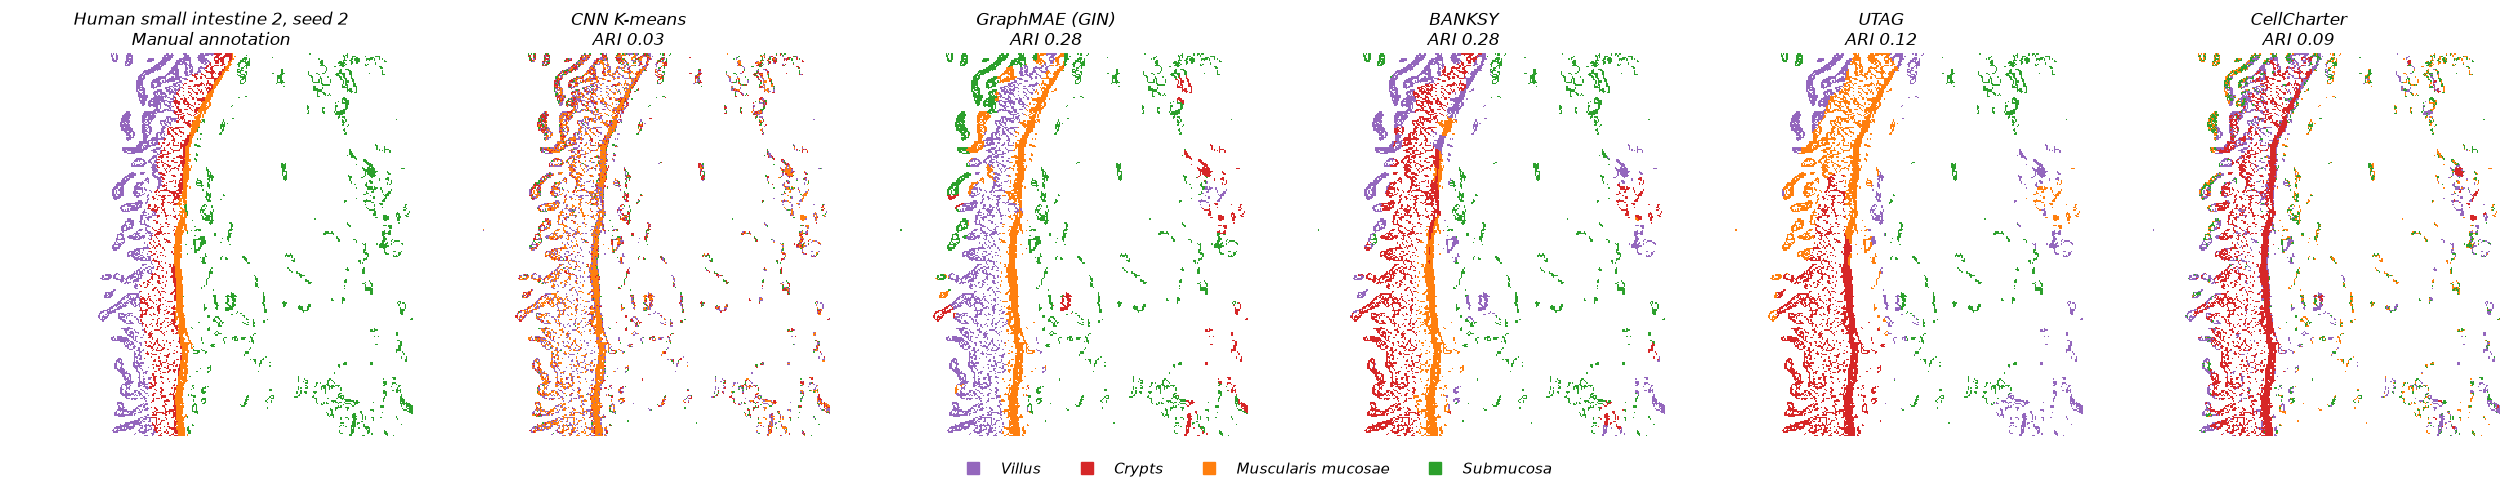

In [9]:
comparison_maps = {}   # seed-0 partitions, for the overview at the end
for key in loaded:
    config, k = SETTINGS[key], SETTINGS[key]["k"]
    selected = {name: entry["config"] for name, entry in config["matched_methods"].items()}
    for seed in ALL["seeds"]["matched"]:
        t = time.perf_counter()
        features = train_cnn(key, seed, config["matched_cnn"]["architecture"], drawn_twice=True)
        with calculation_threads(4):
            partitions = {"CNN K-means": KMeans(n_clusters=k, random_state=seed, **ALL["kmeans"]["matched"]).fit_predict(features)}

        seed_everything(seed, threads=4)
        data = patches[key].copy()
        del data.obsm["image_patches"]
        data.obsm["X_cnn"] = features
        build_selected_graph(data, selected["graphmae"]["k"])
        mt.nn.encode_graphmae(
            data, graph_key="patch", node_feature_key="X_cnn", key_added="X_graphmae",
            n_layers=selected["graphmae"]["depth"], mask_ratio=selected["graphmae"]["mask"],
            random_state=seed, accelerator=DEVICE, enable_progress_bar=False, **ALL["matched_graphmae_fixed"],
        )
        with calculation_threads(4):
            partitions["GraphMAE (GIN)"] = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(
                np.asarray(data.obsm["X_graphmae"], dtype=np.float32))
        release_cuda()

        for name, (setting, run) in COMPARATORS.items():
            seed_everything(seed, threads=4)
            partitions[name] = run_quietly(run, key, features, selected[setting], seed, 10)
        for name, labels in partitions.items():
            record(key, "c, selected", name, seed, labels)
        if seed == 0:
            comparison_maps[key] = partitions
        print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)
        show_maps(key, partitions, f"{TITLES[key]}, seed {seed}")

### Default settings, single runs

BANKSY, UTAG and CellCharter at their default neighbourhood settings, on the seed-0 CNN features of Fig. 2a, b.

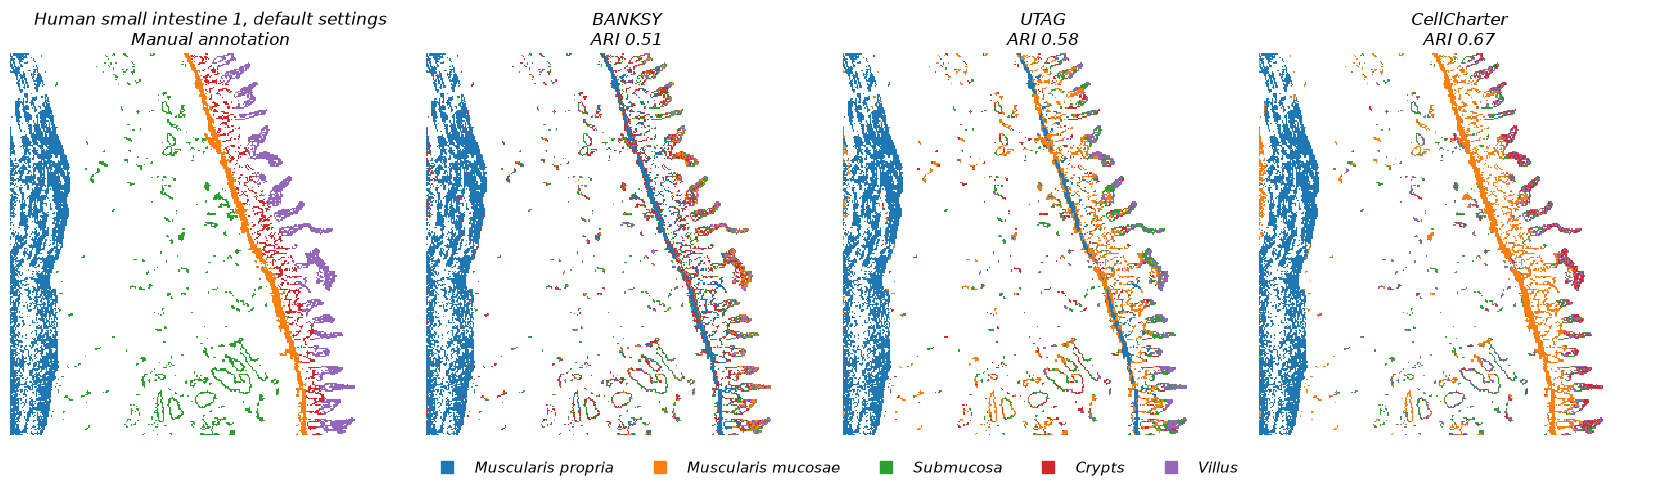

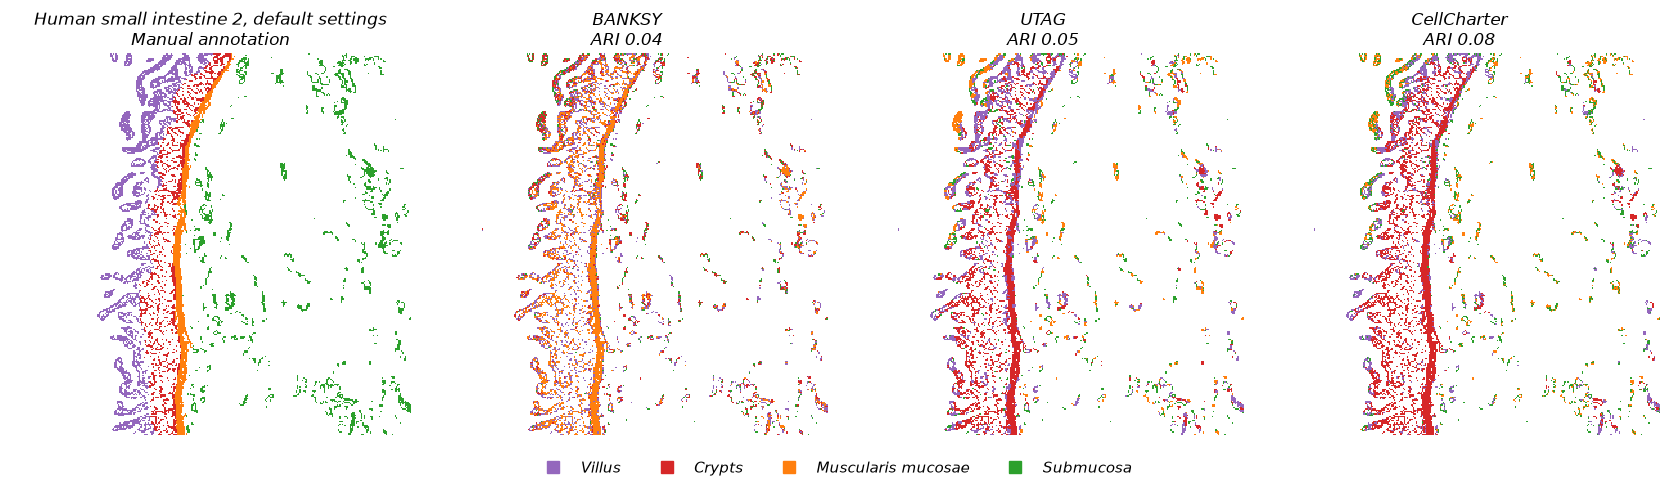

In [10]:
DEFAULTS = {
    "BANKSY": {"k": 15, "lambda": 0.2, "max_m": 1, "pca": 20},
    "UTAG": {"radius_um": 20.0, "pca": 10, "normalization": "l1_norm"},
    "CellCharter": {"graph": "native_knn6", "hops": 3},
}
for key in loaded:
    partitions = {}
    for name, (_, run) in COMPARATORS.items():
        seed_everything(0, threads=4)
        partitions[name] = run_quietly(run, key, joint_features[key, 0], DEFAULTS[name], 0, "auto")
        record(key, "c, default", name, 0, partitions[name])
    show_maps(key, partitions, f"{TITLES[key]}, default settings")

### All methods together

One row per image: every method at its selected settings (seed 0), from no spatial context to the graph methods.
The table and plot then give the scores of every method against the paper (Fig. 2c).

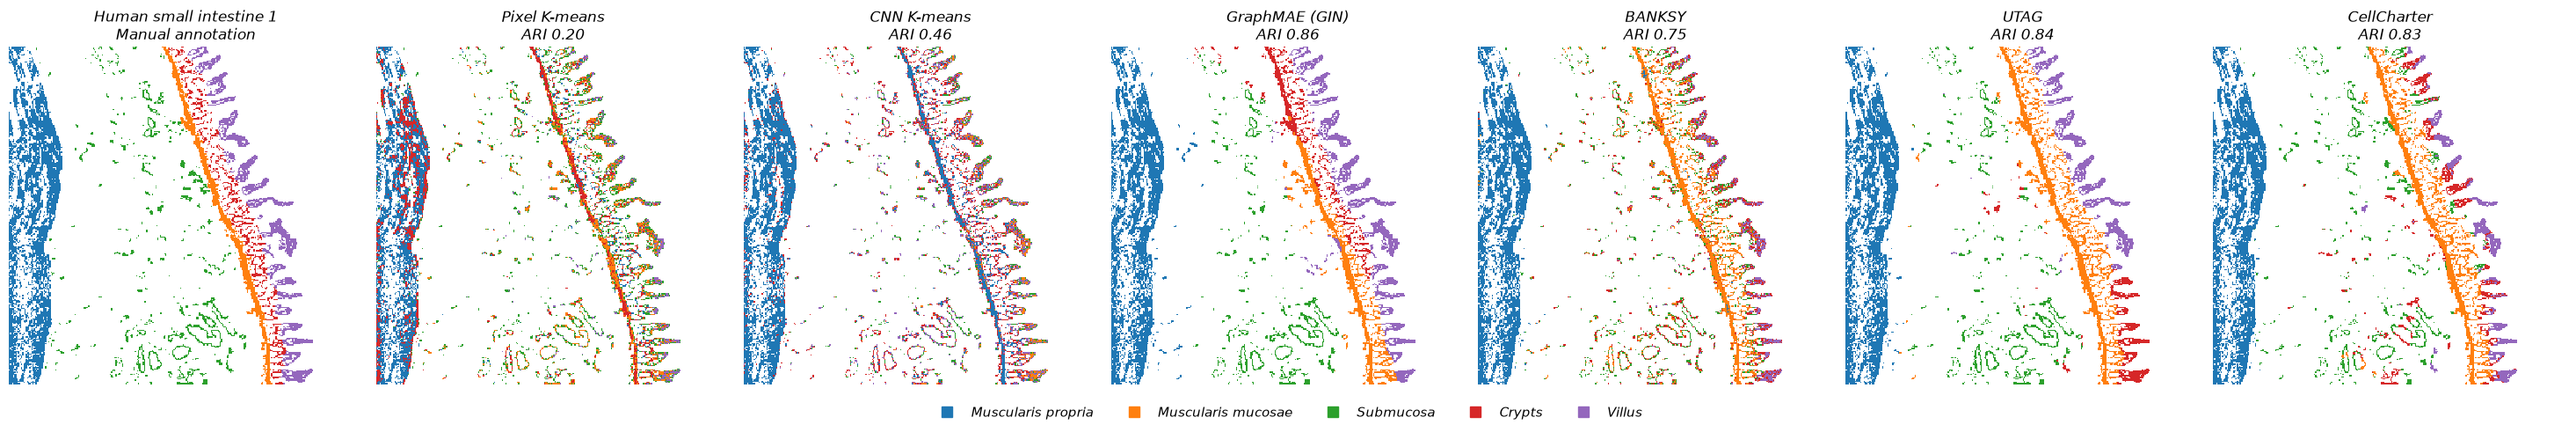

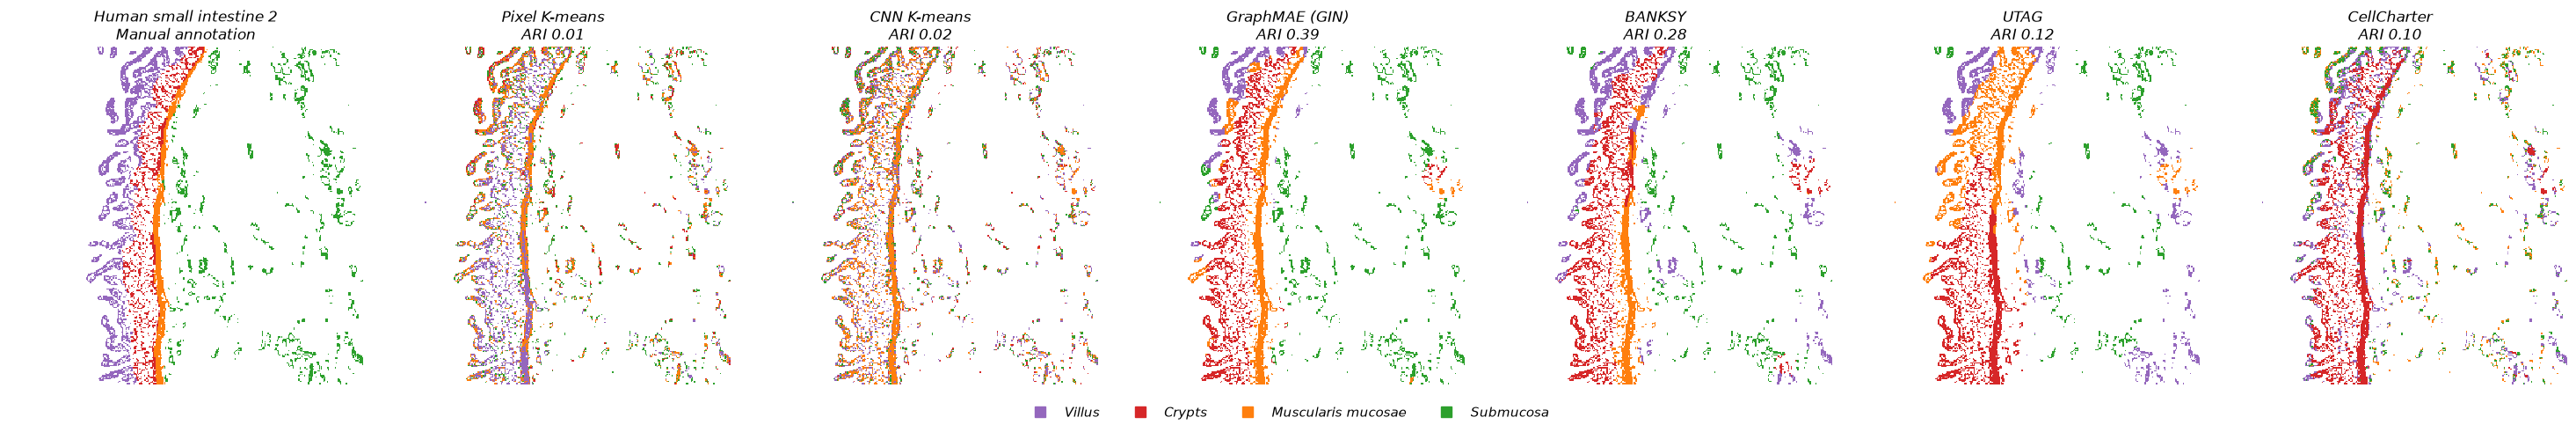

In [11]:
for key, item in loaded.items():
    overview = {"Pixel K-means": shown[key]["Pixel K-means"], **comparison_maps[key]}
    show_maps(key, overview, TITLES[key], ari={"Pixel K-means": item["shown_ari"]["Pixel K-means"]})

### Scores against the paper (Figure 2c)

this run          paper  \
image                   method                                             
Human small intestine 1 GraphMAE (GIN)      0.864 ± 0.006  0.866 ± 0.004   
                        UTAG                0.843 ± 0.001  0.842 ± 0.004   
                        BANKSY              0.757 ± 0.008  0.753 ± 0.006   
                        CellCharter         0.714 ± 0.206  0.831 ± 0.006   
                        CNN K-means         0.469 ± 0.012  0.473 ± 0.012   
                        Patch-mean K-means          0.229          0.229   
                        Multi-Otsu                  0.222          0.222   
                        Pixel K-means               0.196          0.203   
Human small intestine 2 GraphMAE (GIN)      0.354 ± 0.064  0.389 ± 0.003   
                        UTAG                0.123 ± 0.001  0.123 ± 0.001   
                        BANKSY              0.280 ± 0.005  0.282 ± 0.012   
                        CellCharter         0.096 ± 0.003  0.097 ± 0.003   
                        CNN K-means         0.027 ± 0.002  0.027 ± 0.002   
                        Patch-mean K-means          0.018          0.018   
                        Multi-Otsu                  0.018          0.018   
                        Pixel K-means               0.010          0.010   

                                             seeds, this run  \
image                   method                                 
Human small intestine 1 GraphMAE (GIN)      0.86, 0.87, 0.86   
                        UTAG                0.84, 0.84, 0.84   
                        BANKSY              0.75, 0.76, 0.76   
                        CellCharter         0.83, 0.48, 0.84   
                        CNN K-means         0.46, 0.48, 0.46   
                        Patch-mean K-means                     
                        Multi-Otsu                             
                        Pixel K-means                          
Human small intestine 2 GraphMAE (GIN)      0.39, 0.40, 0.28   
                        UTAG                0.12, 0.12, 0.12   
                        BANKSY              0.28, 0.28, 0.28   
                        CellCharter         0.10, 0.10, 0.09   
                        CNN K-means         0.02, 0.03, 0.03   
                        Patch-mean K-means                     
                        Multi-Otsu                             
                        Pixel K-means                          

                                           default, this run default, paper  
image                   method                                               
Human small intestine 1 GraphMAE (GIN)                                       
                        UTAG                           0.582          0.582  
                        BANKSY                         0.509          0.521  
                        CellCharter                    0.671          0.670  
                        CNN K-means                                          
                        Patch-mean K-means                                   
                        Multi-Otsu                                           
                        Pixel K-means                                        
Human small intestine 2 GraphMAE (GIN)                                       
                        UTAG                           0.051          0.051  
                        BANKSY                         0.041          0.040  
                        CellCharter                    0.084          0.097  
                        CNN K-means                                          
                        Patch-mean K-means                                   
                        Multi-Otsu                                           
                        Pixel K-means

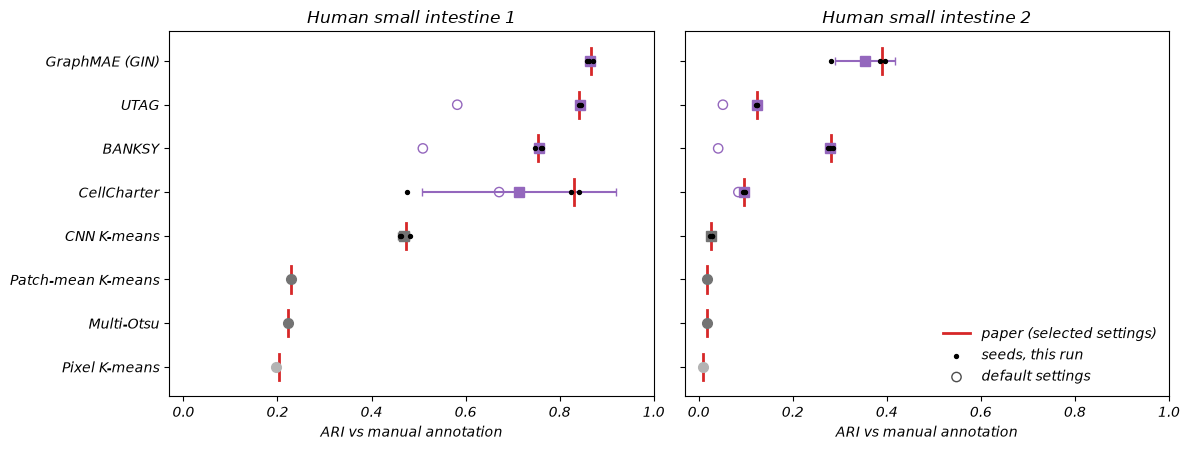

Notebook elapsed: 26.5 min


In [12]:
METHODS = ["GraphMAE (GIN)", "UTAG", "BANKSY", "CellCharter", "CNN K-means", "Patch-mean K-means", "Multi-Otsu", "Pixel K-means"]
PAPER_C = {   # source data fig2.xlsx, sheet c_ari: (selected mean, s.d.), default
    "intestine1": {"GraphMAE (GIN)": ((0.866, 0.004), None), "UTAG": ((0.842, 0.004), 0.582), "BANKSY": ((0.753, 0.006), 0.521),
                   "CellCharter": ((0.831, 0.006), 0.670), "CNN K-means": ((0.473, 0.012), None),
                   "Patch-mean K-means": ((0.229, None), None), "Multi-Otsu": ((0.222, None), None), "Pixel K-means": ((0.203, None), None)},
    "intestine2": {"GraphMAE (GIN)": ((0.389, 0.003), None), "UTAG": ((0.123, 0.001), 0.051), "BANKSY": ((0.282, 0.012), 0.040),
                   "CellCharter": ((0.097, 0.003), 0.097), "CNN K-means": ((0.027, 0.002), None),
                   "Patch-mean K-means": ((0.018, None), None), "Multi-Otsu": ((0.018, None), None), "Pixel K-means": ((0.010, None), None)},
}
table = pd.DataFrame(scores)
c = table[table.panel.str.startswith("c")]
rows = []
for key in loaded:
    for method in METHODS:
        main = c[(c.image == key) & (c.method == method) & (c.panel != "c, default")]["ARI"]
        default = c[(c.image == key) & (c.method == method) & (c.panel == "c, default")]["ARI"]
        (mean, sd), paper_default = PAPER_C[key][method]
        rows.append({
            "image": TITLES[key], "method": method,
            "this run": f"{main.mean():.3f}" + (f" ± {main.std():.3f}" if len(main) > 1 else ""),
            "paper": f"{mean:.3f}" + (f" ± {sd:.3f}" if sd is not None else ""),
            "seeds, this run": ", ".join(f"{v:.2f}" for v in main) if len(main) > 1 else "",
            "default, this run": f"{default.iloc[0]:.3f}" if len(default) else "",
            "default, paper": f"{paper_default:.3f}" if paper_default is not None else "",
        })
display(pd.DataFrame(rows).set_index(["image", "method"]))

figure, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for axis, key in zip(axes, loaded):
    for position, method in enumerate(METHODS[::-1]):
        main = c[(c.image == key) & (c.method == method) & (c.panel != "c, default")]["ARI"].to_numpy()
        default = c[(c.image == key) & (c.method == method) & (c.panel == "c, default")]["ARI"].to_numpy()
        colour = "tab:purple" if position >= 4 else "0.45" if position >= 1 else "0.7"
        axis.errorbar(main.mean(), position, xerr=main.std(ddof=1) if len(main) > 1 else None, color=colour,
                      marker="s" if len(main) > 1 else "o", markersize=7, capsize=3)
        if len(main) > 1:
            axis.scatter(main, np.full(len(main), position), color="black", s=8, zorder=3)
        if len(default):
            axis.scatter(default, [position], facecolors="none", edgecolors=colour, s=45)
        axis.plot([PAPER_C[key][method][0][0]] * 2, [position - 0.3, position + 0.3], color="tab:red", linewidth=2)
    axis.set_yticks(range(len(METHODS)), METHODS[::-1])
    axis.set_xlim(-0.03, 1)
    axis.set_xlabel("ARI vs manual annotation")
    axis.set_title(TITLES[key])
axes[1].plot([], [], color="tab:red", linewidth=2, label="paper (selected settings)")
axes[1].scatter([], [], color="black", s=8, label="seeds, this run")
axes[1].scatter([], [], facecolors="none", edgecolors="0.3", s=45, label="default settings")
axes[1].legend(frameon=False, loc="lower right")
figure.tight_layout()
plt.show()
print(f"Notebook elapsed: {(time.perf_counter() - STARTED) / 60:.1f} min")

[Mantpy](https://github.com/moeghaf/Mantpy) · [image 1](https://doi.org/10.5281/zenodo.21538382) ·
[image 2](https://doi.org/10.5281/zenodo.23740311) · [UTAG](https://github.com/ElementoLab/utag) ·
[BANKSY](https://github.com/prabhakarlab/Banksy_py) · [CellCharter](https://cellcharter.readthedocs.io/en/stable/)